<a href="https://colab.research.google.com/github/Daynomoon/AAI-521-Computer-Vision-Final-Project/blob/custom_cnn/02_Custom_CNN_Development_and_Evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

This notebook focuses on developing, training, and evaluating a custom Convolutional Neural Network (CNN) for traffic sign classification using the previously prepared GTSRB dataset.

The model will be evaluated under normal and challenging visual conditions, including reduced brightness, motion blur, and image noise. The results will be compared with the pretrained MobileNetV2 model.

In [1]:
# Import Libraries
import os
import json
import zipfile
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, callbacks

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
# Load Shared Preprocessing Outputs
# Clone the shared GitHub repository
!git clone https://github.com/Daynomoon/AAI-521-Computer-Vision-Final-Project.git

Cloning into 'AAI-521-Computer-Vision-Final-Project'...
remote: Enumerating objects: 27, done.
remote: Counting objects: 100% (27/27), done.
remote: Compressing objects: 100% (27/27), done.
remote: Total 27 (delta 5), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (27/27), 2.85 MiB | 5.28 MiB/s, done.
Resolving deltas: 100% (5/5), done.


In [3]:
# Define the project directory
PROJECT_DIR = Path(
    "/content/AAI-521-Computer-Vision-Final-Project"
)

# Display repository contents
for file in PROJECT_DIR.iterdir():
    print(file.name)

.gitignore
GTSRB_Preprocessing_Outputs.zip
AI_521_Final_Project_7_1_GTSRB_.ipynb
README.md
.git


In [4]:
# Define the preprocessing ZIP file path
ZIP_PATH = PROJECT_DIR / "GTSRB_Preprocessing_Outputs.zip"

# Define the output directory
OUTPUT_DIR = Path("/content/GTSRB_Preprocessing_Outputs")

# Extract preprocessing files
with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(OUTPUT_DIR)

print("Preprocessing files extracted successfully.")

# Display extracted files
for file in sorted(OUTPUT_DIR.rglob("*")):
    if file.is_file():
        print(file.relative_to(OUTPUT_DIR))

Preprocessing files extracted successfully.
class_distribution.csv
figures/class_distribution.png
figures/preprocessing_comparison.png
preprocessing_settings.json
splits/test_split.csv
splits/train_split.csv
splits/val_split.csv


In [5]:
# Locate the shared preprocessing settings
settings_path = next(
    OUTPUT_DIR.rglob("preprocessing_settings.json")
)

# Load preprocessing settings
with open(settings_path, "r") as f:
    settings = json.load(f)

# Display preprocessing configuration
print(json.dumps(settings, indent=4))

{
    "dataset": "GTSRB",
    "source": "meowmeowmeowmeowmeow/gtsrb-german-traffic-sign",
    "image_size": [
        128,
        128
    ],
    "color_mode": "RGB",
    "normalization": "0 to 1",
    "batch_size": 32,
    "number_of_classes": 43,
    "random_seed": 42,
    "split_method": "GroupShuffleSplit",
    "validation_fraction_of_groups": 0.2,
    "grouping_method": "Class folder and filename sequence prefix",
    "augmentation": {
        "rotation": 0.05,
        "zoom": 0.1,
        "brightness": 0.15,
        "applied_during_preparation": false
    },
    "mobilenetv2_note": "Use preprocessing compatible with pretrained MobileNetV2 weights during model training.",
    "training_images": 30869,
    "validation_images": 8340,
    "testing_images": 12630
}


In [6]:
# Load shared training, validation, and testing splits
train_df = pd.read_csv(
    next(OUTPUT_DIR.rglob("train_split.csv"))
)

val_df = pd.read_csv(
    next(OUTPUT_DIR.rglob("val_split.csv"))
)

test_df = pd.read_csv(
    next(OUTPUT_DIR.rglob("test_split.csv"))
)

# Display dataset sizes
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

# Preview the training dataset
display(train_df.head())

Training images: 30869
Validation images: 8340
Testing images: 12630


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,33,29,6,5,28,24,18,Train/18/00018_00034_00000.png
1,130,137,11,12,119,126,38,Train/38/00038_00023_00029.png
2,45,45,5,5,40,40,10,Train/10/00010_00048_00020.png
3,32,31,6,6,27,26,5,Train/5/00005_00058_00011.png
4,88,83,8,8,81,75,25,Train/25/00025_00041_00022.png


### Dataset Acquisition
Download the original GTSRB images and match them with the shared dataset splits.

In [7]:
import kagglehub

# Download the original GTSRB dataset
DATA_DIR = Path(kagglehub.dataset_download(
    "meowmeowmeowmeowmeow/gtsrb-german-traffic-sign"
))

# Verify image paths across all dataset splits
for name, df in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    missing = sum(
        not (DATA_DIR / path).is_file()
        for path in df["Path"]
    )

    assert missing == 0, f"{name}: {missing} missing images."

print("All dataset image paths verified successfully.")

Using Colab cache for faster access to the 'gtsrb-german-traffic-sign' dataset.
All dataset image paths verified successfully.


### TensorFlow Data Pipeline

The shared preprocessing configuration and dataset splits are used to construct TensorFlow datasets for model training, validation, and testing. Data augmentation is applied only during training to improve model generalization.

In [8]:
# Reuse shared preprocessing settings
IMG_SIZE = tuple(settings["image_size"])
BATCH_SIZE = settings["batch_size"]
NUM_CLASSES = settings["number_of_classes"]
SEED = settings["random_seed"]

keras.utils.set_random_seed(SEED)

In [9]:
# Load and preprocess images
def load_image_tf(path, label):
    image = tf.io.read_file(path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0

    return image, label


# Construct TensorFlow datasets
def create_dataset(dataframe, shuffle=False):
    paths = [
        str(DATA_DIR / path)
        for path in dataframe["Path"]
    ]

    labels = dataframe["ClassId"].astype("int32").values

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=SEED
        )

    return (
        dataset
        .map(load_image_tf, num_parallel_calls=tf.data.AUTOTUNE)
        .batch(BATCH_SIZE)
        .prefetch(tf.data.AUTOTUNE)
    )


# Create datasets using the existing splits
train_ds = create_dataset(train_df, shuffle=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

In [10]:
# Reuse shared augmentation settings
augmentation = settings["augmentation"]

data_augmentation = keras.Sequential([
    layers.RandomRotation(augmentation["rotation"]),
    layers.RandomZoom(augmentation["zoom"]),
    layers.RandomBrightness(
        factor=augmentation["brightness"],
        value_range=(0.0, 1.0)
    )
], name="data_augmentation")

In [11]:
# Verify the input dimensions and labels
images, labels = next(iter(train_ds))

print("Input batch shape:", images.shape)
print("Label batch shape:", labels.shape)

Input batch shape: (32, 128, 128, 3)
Label batch shape: (32,)


### Custom CNN Architecture

A custom Convolutional Neural Network (CNN) will be developed from scratch to classify traffic signs across 43 categories.

The architecture uses convolutional layers for feature extraction, batch normalization for training stability, max pooling for spatial dimensionality reduction, and dropout to reduce overfitting. Global average pooling is used to reduce model complexity before classification.

In [12]:
def build_cnn(learning_rate=0.001, dropout_rate=0.3):

    model = keras.Sequential([
        layers.Input(shape=(*IMG_SIZE, 3)),

        data_augmentation,

        # Convolutional block 1
        layers.Conv2D(32, 3, padding="same"),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D(2),

        # Convolutional block 2
        layers.Conv2D(64, 3, padding="same"),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D(2),

        # Convolutional block 3
        layers.Conv2D(128, 3, padding="same"),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D(2),

        # Convolutional block 4
        layers.Conv2D(256, 3, padding="same"),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D(2),

        # Classification layers
        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(dropout_rate),
        layers.Dense(NUM_CLASSES, activation="softmax")

    ], name="Custom_CNN")

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


# Initialize baseline model
model = build_cnn()
model.summary()

Model: "Custom_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 43)             │         5,547 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 428,779 (1.64 MB)

 Trainable params: 427,819 (1.63 MB)

 Non-trainable params: 960 (3.75 KB)

### Baseline Model Training

The baseline CNN will be trained using the Adam optimizer
with an initial learning rate of 0.001 and a dropout rate
of 0.3.

Early stopping and learning rate reduction will be used
to improve training efficiency and reduce overfitting.
The best model weights will be selected based on
validation loss.

In [14]:
#Training configuration
EPOCHS = 30

def get_callbacks():
    return [
        callbacks.EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True
        ),

        callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=2,
            min_lr=1e-6
        )
    ]

In [15]:
#Train the baseline model
start_time = time.time()

baseline_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=get_callbacks(),
    verbose=2
)

baseline_training_time = time.time() - start_time

print(
    f"Training time: "
    f"{baseline_training_time / 60:.2f} minutes"
)

Epoch 1/30
965/965 - 121s - 125ms/step - accuracy: 0.1933 - loss: 2.8836 - val_accuracy: 0.2327 - val_loss: 2.6795 - learning_rate: 0.0010
Epoch 2/30
965/965 - 52s - 54ms/step - accuracy: 0.3820 - loss: 2.0262 - val_accuracy: 0.3659 - val_loss: 2.1861 - learning_rate: 0.0010
Epoch 3/30
965/965 - 82s - 85ms/step - accuracy: 0.5253 - loss: 1.4831 - val_accuracy: 0.4802 - val_loss: 1.5890 - learning_rate: 0.0010
Epoch 4/30
965/965 - 53s - 55ms/step - accuracy: 0.6515 - loss: 1.0916 - val_accuracy: 0.5718 - val_loss: 1.4367 - learning_rate: 0.0010
Epoch 5/30
965/965 - 56s - 59ms/step - accuracy: 0.7582 - loss: 0.7573 - val_accuracy: 0.7507 - val_loss: 0.8264 - learning_rate: 0.0010
Epoch 6/30
965/965 - 52s - 54ms/step - accuracy: 0.8322 - loss: 0.5390 - val_accuracy: 0.8144 - val_loss: 0.5975 - learning_rate: 0.0010
Epoch 7/30
965/965 - 52s - 54ms/step - accuracy: 0.8729 - loss: 0.4130 - val_accuracy: 0.8440 - val_loss: 0.4933 - learning_rate: 0.0010
Epoch 8/30
965/965 - 57s - 59ms/step - 

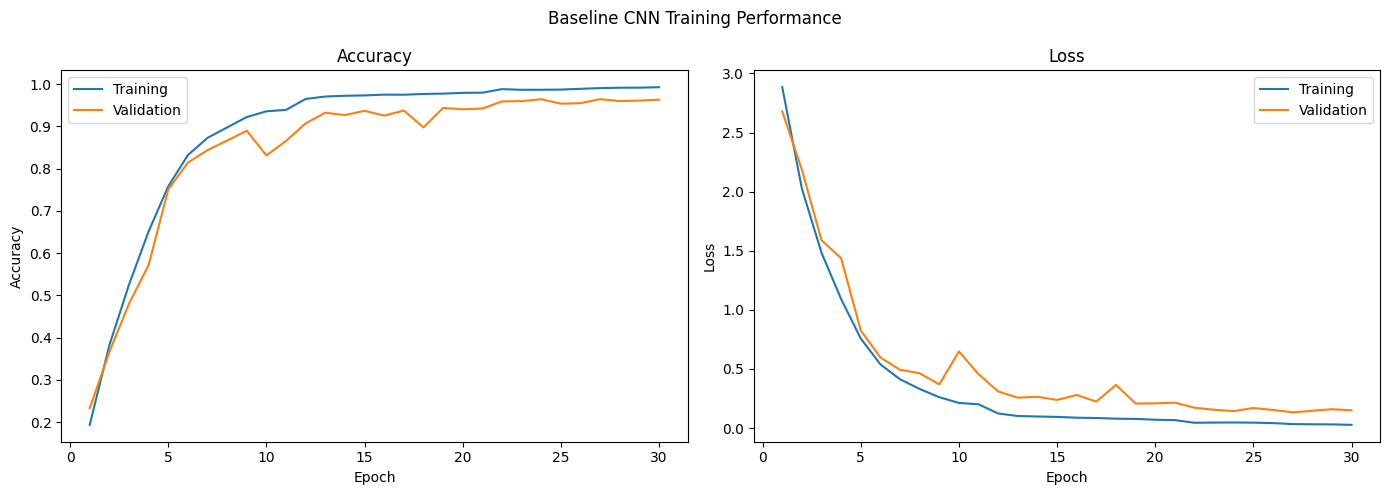

In [18]:
#Visualize baseline training
def plot_training_history(history, title):
    hist = history.history
    epochs = range(1, len(hist["accuracy"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    for ax, metric, label in [
        (axes[0], "accuracy", "Accuracy"),
        (axes[1], "loss", "Loss")
    ]:
        ax.plot(epochs, hist[metric], label="Training")
        ax.plot(
            epochs,
            hist[f"val_{metric}"],
            label="Validation"
        )

        ax.set_title(label)
        ax.set_xlabel("Epoch")
        ax.set_ylabel(label)
        ax.legend()

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


plot_training_history(
    baseline_history,
    "Baseline CNN Training Performance"
)

In [20]:
RESULTS_DIR = Path("/content/Custom_CNN_Outputs")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Save baseline model
model.save(RESULTS_DIR / "baseline_cnn.keras")

# Save baseline training history
pd.DataFrame(baseline_history.history).to_csv(
    RESULTS_DIR / "baseline_history.csv",
    index=False
)

# Save baseline training time
with open(RESULTS_DIR / "baseline_training_time.json", "w") as f:
    json.dump({"training_time": baseline_training_time}, f)

### Hyperparameter Tuning

Hyperparameter tuning will investigate the effects of
learning rate and dropout on model performance.
Two additional configurations will be evaluated while
keeping the architecture, preprocessing, dataset splits,
and training conditions consistent.

The best configuration will be selected based on the
lowest validation loss.